In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import root_mean_squared_error
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import ExponentialSmoothing
from statsmodels.tsa.api import Holt
from pmdarima.arima import auto_arima
from statsmodels.tsa.api import SimpleExpSmoothing
from tqdm import  tqdm
import warnings
warnings.filterwarnings('ignore')
import os
os.chdir('E:/Machine_Learning/Datasets/')

In [2]:
df = pd.read_csv('AusGas.csv')
df.head()

,Month,GasProd
0,Jan-1956,1709
1,Feb-1956,1646
2,Mar-1956,1794
3,Apr-1956,1878
4,May-1956,2173


In [3]:
y = df['GasProd']
y_train = y[:-12]
y_test = y[-12:]

### SimpleExpSmoothing

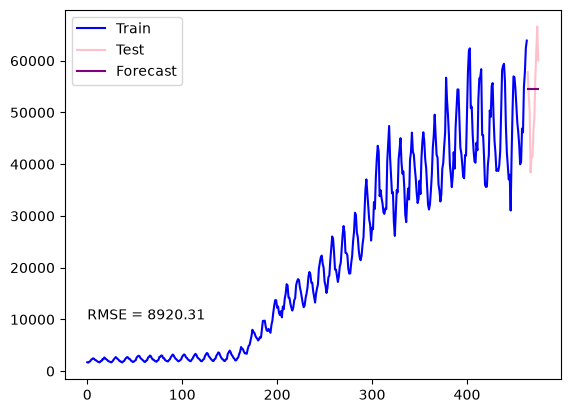

In [4]:
alpha = 0.2
ses = SimpleExpSmoothing(y_train, initialization_method='estimated')
fit1 = ses.fit(smoothing_level=alpha)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(0,10000,f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()

### Holt's Linear Trend

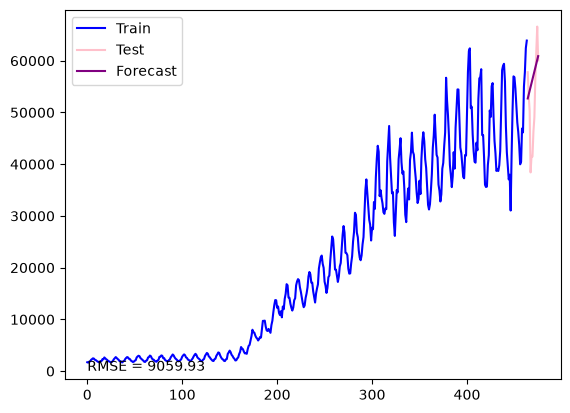

In [5]:
alpha,beta = 0.1,0.2
holt  = Holt(y_train, initialization_method='estimated')
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(00,60, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


### Holt's Exponential Trend

In [6]:
alpha,beta = 0.1,0.2
alpha = np.linspace(0.01,0.99,10)
beta = np.linspace(0.01,0.99,10)
scores = []
for a in tqdm(alpha):
    for b in beta:
        for e in [True,False]:
            holt  = Holt(y_train, initialization_method='estimated',exponential=e)
            fit1 = holt.fit(smoothing_level=a,smoothing_trend=b)
            fcast1 = fit1.forecast(len(y_test))
            scores.append([a,b,e,root_mean_squared_error(y_test,fcast1)])

df_scores = pd.DataFrame(scores,columns=['alpha','beta','Exponential','score'])
df_scores.sort_values('score',ascending=True)

100%|██████████| 10/10 [00:05<00:00,  1.93it/s]


,alpha,beta,Exponential,score
14,0.010000,0.772222,True,7.527528e+03
15,0.010000,0.772222,False,7.618185e+03
4,0.010000,0.227778,True,8.024419e+03
13,0.010000,0.663333,False,8.336440e+03
2,0.010000,0.118889,True,8.416666e+03
...,...,...,...,...
72,0.336667,0.663333,True,1.216516e+05
54,0.227778,0.772222,True,1.406597e+05
56,0.227778,0.881111,True,2.117923e+05
58,0.227778,0.990000,True,2.717651e+05


## Seasonal Exponential

In [7]:
alpha = np.linspace(0.01,0.99,10)
beta = np.linspace(0.01,0.99,10)
gamma = np.linspace(0.01,0.99,10)
scores = []

for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
            for s in ['add','mul']:
                hw_add = ExponentialSmoothing(y_train,seasonal_periods=12,trend = 'add',seasonal = s)
                fit1 = hw_add.fit(smoothing_level = a ,smoothing_trend = b ,smoothing_seasonal = g)
                fcast1 = fit1.forecast(len(y_test))
                scores.append([s,a,b,g,root_mean_squared_error(y_test,fcast1)])

df_scores = pd.DataFrame(scores,columns=['seasonality','alpha','beta','gamma','score'])
df_scores.sort_values('score',ascending=True)

100%|██████████| 10/10 [03:36<00:00, 21.68s/it]


,seasonality,alpha,beta,gamma,score
481,mul,0.227778,0.445556,0.010000,2.295494e+03
811,mul,0.445556,0.010000,0.554444,2.335206e+03
403,mul,0.227778,0.010000,0.118889,2.342193e+03
850,add,0.445556,0.227778,0.554444,2.346541e+03
603,mul,0.336667,0.010000,0.118889,2.352316e+03
...,...,...,...,...,...
1851,mul,0.990000,0.227778,0.554444,8.082335e+07
1591,mul,0.772222,0.990000,0.554444,8.362873e+07
1996,add,0.990000,0.990000,0.881111,2.350540e+09
1978,add,0.990000,0.881111,0.990000,9.565620e+09


### Best model by  Seasonal Exponential

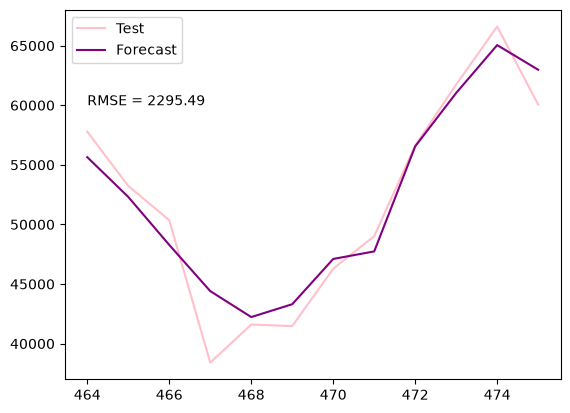

In [8]:
hw_add = ExponentialSmoothing(y_train,seasonal_periods=12,trend = 'add',seasonal = 'mul')
fit1 = hw_add.fit(smoothing_level = 0.227778 ,smoothing_trend = 0.445556 ,smoothing_seasonal = 0.01)
fcast1 = fit1.forecast(len(y_test))

y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(464,60000,f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()

## ARIMA

In [9]:
model = ARIMA(y_train,order=(2,1,1))
model_fit = model.fit()
print('Coefficient: %s' % model_fit.params)
predictions = model_fit.predict(start = len(y_train),end = len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test,predictions)
print('Test RMSE : %.3f' % error)

Coefficient: ar.L1    -1.425393e-02
ar.L2     2.638232e-01
ma.L1     2.726234e-01
sigma2    6.250386e+06
dtype: float64
Test RMSE : 16411.416


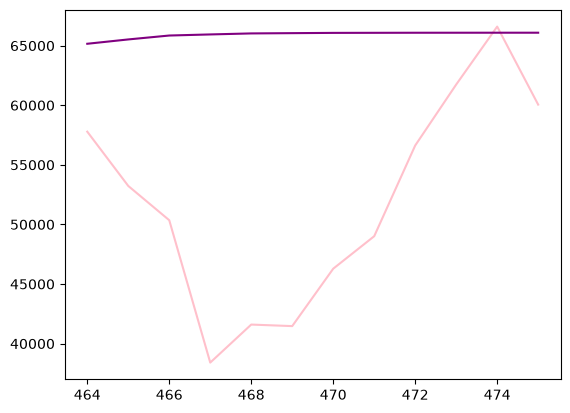

In [10]:
y_test.plot(color = 'pink')
predictions.plot(color = 'purple')
plt.show()

# AutoARIMA

In [11]:
model = auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=8355.115, Time=1.58 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=8632.352, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=8589.946, Time=0.03 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=8603.593, Time=0.07 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=8631.502, Time=0.01 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=8571.932, Time=0.57 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=8577.053, Time=0.15 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=8326.858, Time=1.79 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=8426.132, Time=1.34 sec
 ARIMA(4,1,2)(0,0,0)[0] intercept   : AIC=8270.030, Time=2.54 sec
 ARIMA(4,1,1)(0,0,0)[0] intercept   : AIC=8404.137, Time=1.78 sec
 ARIMA(5,1,2)(0,0,0)[0] intercept   : AIC=8391.024, Time=2.23 sec
 ARIMA(4,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.66 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.01 sec
 ARIMA(5,1,1)(0,0,0)[0] intercept   : AIC=8

In [12]:
forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast,index=y_test.index,columns=['Prediction'])
rms = root_mean_squared_error(y_test,forecast)
print('Test RMSE : %.3f' % rms)

Test RMSE : 2575.989


In [13]:
forecast

,Prediction
464,60114.434246
465,54760.752725
466,49262.210963
467,44793.210272
468,42149.798947
469,42239.993343
470,45070.929185
471,49881.258974
472,55335.287635
473,60000.477085


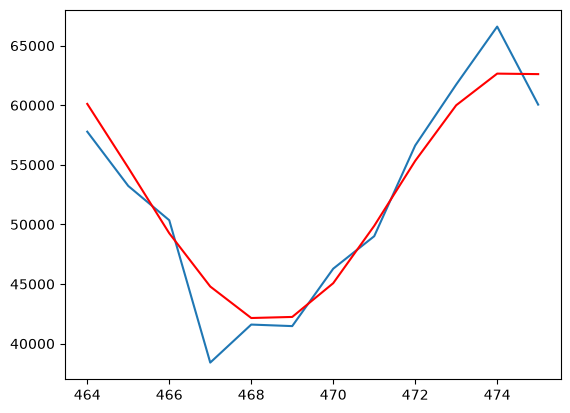

In [14]:
plt.plot(y_test)
plt.plot(forecast, color='red')
plt.show()

## SARIMA

In [15]:
model = auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True,seasonal=True,m=12)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=inf, Time=3.99 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=8632.352, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=8255.565, Time=1.24 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=8438.509, Time=1.06 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=8631.502, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=8589.946, Time=0.03 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : AIC=inf, Time=2.84 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : AIC=8170.931, Time=2.80 sec
 ARIMA(1,1,0)(0,0,1)[12] intercept   : AIC=8438.053, Time=0.83 sec
 ARIMA(1,1,0)(2,0,1)[12] intercept   : AIC=8218.685, Time=5.29 sec
 ARIMA(1,1,0)(1,0,2)[12] intercept   : AIC=8204.884, Time=5.83 sec
 ARIMA(1,1,0)(0,0,2)[12] intercept   : AIC=8371.138, Time=2.29 sec
 ARIMA(1,1,0)(2,0,2)[12] intercept   : AIC=inf, Time=6.01 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=8219.426, Time=1.51 sec
 ARIMA(2,1,0)(1,0,1)[12] intercept

In [24]:
forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast,index=y_test.index,columns=['Prediction'])
rms = root_mean_squared_error(y_test,forecast)
print('Test RMSE : %.3f' % rms)

Test RMSE : 3448.997


In [25]:
forecast

,Prediction
464,57530.605933
465,53265.275906
466,49540.694545
467,47290.865410
468,45148.629618
469,45401.699547
470,47327.870869
471,49833.535010
472,58217.616015
473,62438.880829


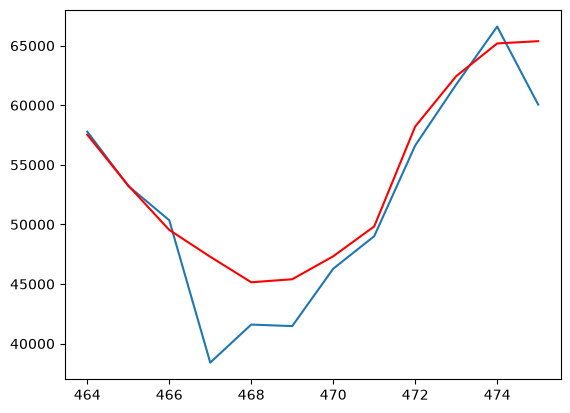

In [26]:
plt.plot(y_test)
plt.plot(forecast, color='red')
plt.show()

### Using BoxCox EndogTransformer

In [19]:
from pmdarima.pipeline import Pipeline
from pmdarima.preprocessing import BoxCoxEndogTransformer
import pmdarima as pm

In [20]:
pipeline = Pipeline([
    ('boxcox',BoxCoxEndogTransformer()),
    ('model',pm.AutoARIMA(seasonal = True,suppress_warnings = True,m=12))
])
pipeline.fit(y_train)

,steps,"[('boxcox', ...), ('model', ...)]"
Name,Type,Value
n_samples_,int,464
steps_,list,"[('boxcox', BoxCoxEndogTransformer()), ('model', AutoARIMA(m=12))]"
x_feats_,NoneType,None


In [27]:
forecast = pipeline.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast,index=y_test.index,columns=['Prediction'])
rms = root_mean_squared_error(y_test,forecast)
print('Test RMSE : %.3f' % rms)

Test RMSE : 3593.527
